In [1]:
# Importar librerías
import pandas as pd
from sodapy import Socrata

# Conectar a la API de datos.gov.co
client = Socrata("www.datos.gov.co", None)

# Descargar TODOS los registros disponibles
print("⏳ Descargando datos... esto puede tardar varios minutos.")
results = client.get("d5t8-3yqf", limit=1000000)

# Convertir a DataFrame
df_full = pd.DataFrame.from_records(results)

# Ver resultados
print(f"\n✅ Descarga completada")
print(f"Filas: {df_full.shape[0]}")
print(f"Columnas: {df_full.shape[1]}")
print(f"\nPrimeras 5 filas:")
df_full.head()

⏳ Descargando datos... esto puede tardar varios minutos.

✅ Descarga completada
Filas: 36613
Columnas: 51

Primeras 5 filas:


,periodo,estu_tipodocumento,estu_consecutivo,cole_area_ubicacion,cole_bilingue,cole_calendario,cole_caracter,cole_cod_dane_establecimiento,cole_cod_dane_sede,cole_cod_depto_ubicacion,...,fami_tienecomputador,fami_tieneinternet,fami_tienelavadora,desemp_ingles,punt_ingles,punt_matematicas,punt_sociales_ciudadanas,punt_c_naturales,punt_lectura_critica,punt_global
0,20132,TI,SB11201320260952,URBANO,N,A,TÉCNICO/ACADÉMICO,115491000017,115491000017,15,...,Si,No,No,A-,43,46,NaN,NaN,NaN,NaN
1,20162,CC,SB11201620253914,URBANO,N,A,TÉCNICO/ACADÉMICO,115759001887,115759001887,15,...,Si,Si,No,A1,52,65,56,61,49,287
2,20172,TI,SB11201720214776,URBANO,N,A,TÉCNICO/ACADÉMICO,115759000473,115759000473,15,...,Si,Si,Si,A1,57,63,59,54,58,292
3,20152,TI,SB11201520154501,URBANO,N,A,TÉCNICO/ACADÉMICO,115759001615,115759001615,15,...,No,No,Si,A1,57,62,63,57,59,300
4,20162,TI,SB11201620555095,URBANO,N,A,ACADÉMICO,315759001576,315759001576,15,...,Si,Si,Si,A-,37,39,34,35,40,185


In [2]:
# Verificar cuántos registros tienen punt_global completo
print("=== VERIFICACIÓN DEL DATASET ===")
print(f"Total de registros: {len(df_full):,}")
print(f"Total de columnas: {df_full.shape[1]}")

# Ver % de punt_global completo
if 'punt_global' in df_full.columns:
    completos = df_full['punt_global'].notna().sum()
    print(f"\nRegistros con punt_global: {completos:,}")
    print(f"Porcentaje con punt_global: {completos/len(df_full)*100:.2f}%")

# Ver periodos disponibles
if 'periodo' in df_full.columns:
    print(f"\nPeriodos disponibles:")
    print(df_full['periodo'].value_counts().sort_index())

=== VERIFICACIÓN DEL DATASET ===
Total de registros: 36,613
Total de columnas: 51

Registros con punt_global: 23,474
Porcentaje con punt_global: 64.11%

Periodos disponibles:
periodo
20101     148
20102    3134
20111     160
20112    3258
20121     213
20122    3013
20131     218
20132    2863
20141     132
20142    2918
20151     155
20152    2873
20162    2893
20172    2884
20181      53
20194    5858
20201      63
20211      42
20221      75
20224    5660
Name: count, dtype: int64


In [3]:
# Ver valores únicos de variables clave
columnas_clave = ['estu_genero', 'cole_area_ubicacion', 'cole_caracter',
                  'cole_jornada', 'fami_estratovivienda', 'fami_educacionmadre']

for col in columnas_clave:
    if col in df_full.columns:
        print(f"\n{col}:")
        print(df_full[col].value_counts())


estu_genero:
estu_genero
F    19347
M    17217
Name: count, dtype: int64

cole_area_ubicacion:
cole_area_ubicacion
URBANO    33185
RURAL      3398
Name: count, dtype: int64

cole_caracter:
cole_caracter
TÉCNICO/ACADÉMICO    21305
ACADÉMICO             9706
TÉCNICO               5287
NO APLICA              238
Name: count, dtype: int64

cole_jornada:
cole_jornada
MAÑANA      17943
COMPLETA    11295
TARDE        3826
SABATINA     1510
UNICA        1096
NOCHE         943
Name: count, dtype: int64

fami_estratovivienda:
fami_estratovivienda
Estrato 2      21549
Estrato 1       8960
Estrato 3       4158
Estrato 4        639
Sin Estrato      141
Estrato 5        117
Estrato 6         29
Name: count, dtype: int64

fami_educacionmadre:
fami_educacionmadre
Secundaria (Bachillerato) completa      8637
Primaria incompleta                     6203
Primaria completa                       5828
Secundaria (Bachillerato) incompleta    5511
Educación profesional completa          3308
Técnica o tecnol

In [4]:
# ============================================
# ETL - PASO 1: Crear variable objetivo
# ============================================

# 1. Convertir punt_global a numérico (por si acaso)
df_full['punt_global'] = pd.to_numeric(df_full['punt_global'], errors='coerce')

# 2. Eliminar registros sin punt_global (no podemos crear el target sin ellos)
df_clean = df_full.dropna(subset=['punt_global']).copy()

print(f"Registros originales: {len(df_full):,}")
print(f"Registros con punt_global: {len(df_clean):,}")
print(f"Registros eliminados: {len(df_full) - len(df_clean):,}")

# 3. Crear variable objetivo binaria
# Basado en MEN (2009): puntajes bajos = mayor riesgo de deserción
umbral = df_clean['punt_global'].quantile(0.33)
df_clean['riesgo_desercion'] = (df_clean['punt_global'] < umbral).astype(int)

print(f"\nUmbral de puntaje bajo (percentil 33): {umbral:.2f}")
print(f"\nDistribución de riesgo_desercion:")
print(df_clean['riesgo_desercion'].value_counts())
print(f"\nPorcentaje:")
print(df_clean['riesgo_desercion'].value_counts(normalize=True) * 100)

Registros originales: 36,613
Registros con punt_global: 23,474
Registros eliminados: 13,139

Umbral de puntaje bajo (percentil 33): 249.00

Distribución de riesgo_desercion:
riesgo_desercion
0    15792
1     7682
Name: count, dtype: int64

Porcentaje:
riesgo_desercion
0    67.274431
1    32.725569
Name: proportion, dtype: float64


In [5]:
# ============================================
# ETL - PASO 2: Verificar tipos de datos
# ============================================

# Ver tipos actuales
print("Tipos de datos actuales:")
print(df_clean.dtypes.value_counts())

# Convertir variables numéricas que están como object
columnas_numericas = ['punt_ingles', 'punt_matematicas', 'punt_sociales_ciudadanas',
                      'punt_c_naturales', 'punt_lectura_critica', 'punt_global']

for col in columnas_numericas:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

print("\nTipos después de conversión:")
print(df_clean[columnas_numericas].dtypes)

Tipos de datos actuales:
object     50
float64     1
int64       1
Name: count, dtype: int64

Tipos después de conversión:
punt_ingles                   int64
punt_matematicas              int64
punt_sociales_ciudadanas      int64
punt_c_naturales              int64
punt_lectura_critica          int64
punt_global                 float64
dtype: object


In [6]:
# ============================================
# ETL - PASO 3: Verificar duplicados
# ============================================

# Ver duplicados por estu_consecutivo (ID del estudiante)
duplicados = df_clean.duplicated(subset=['estu_consecutivo']).sum()
print(f"Registros duplicados por estu_consecutivo: {duplicados}")

# Eliminar duplicados
df_clean = df_clean.drop_duplicates(subset=['estu_consecutivo'], keep='first')

print(f"\nRegistros después de eliminar duplicados: {len(df_clean):,}")

Registros duplicados por estu_consecutivo: 5759

Registros después de eliminar duplicados: 17,715


In [7]:
# ============================================
# ETL - PASO 4: Tratar faltantes
# ============================================

# Ver faltantes ANTES
print("=== FALTANTES ANTES DE IMPUTACIÓN ===")
faltantes_antes = df_clean.isnull().sum()
faltantes_antes = faltantes_antes[faltantes_antes > 0].sort_values(ascending=False)
print(faltantes_antes)

# Estrategia: imputar con la moda para variables categóricas
# y con la mediana para variables numéricas

# Variables categóricas socioeconómicas
cols_categoricas = ['fami_estratovivienda', 'fami_educacionmadre',
                    'fami_educacionpadre', 'fami_tienecomputador',
                    'fami_tieneinternet', 'fami_tieneautomovil',
                    'fami_tienelavadora', 'cole_area_ubicacion',
                    'cole_caracter', 'cole_jornada', 'estu_genero']

for col in cols_categoricas:
    if col in df_clean.columns:
        moda = df_clean[col].mode()[0]
        df_clean[col] = df_clean[col].fillna(moda)

# Variables numéricas (puntajes)
cols_numericas = ['punt_ingles', 'punt_matematicas']

for col in cols_numericas:
    if col in df_clean.columns:
        mediana = df_clean[col].median()
        df_clean[col] = df_clean[col].fillna(mediana)

# Ver faltantes DESPUÉS
print("\n=== FALTANTES DESPUÉS DE IMPUTACIÓN ===")
faltantes_despues = df_clean.isnull().sum()
faltantes_despues = faltantes_despues[faltantes_despues > 0].sort_values(ascending=False)
print(faltantes_despues if len(faltantes_despues) > 0 else "No hay faltantes")

=== FALTANTES ANTES DE IMPUTACIÓN ===
cole_bilingue            779
fami_estratovivienda     480
fami_tieneinternet       442
fami_educacionpadre      424
fami_educacionmadre      422
fami_personashogar       268
fami_cuartoshogar        250
fami_tieneautomovil      249
fami_tienecomputador     244
fami_tienelavadora       240
estu_genero               47
estu_cod_reside_depto     45
estu_cod_reside_mcpio     45
estu_mcpio_reside         45
estu_depto_reside         45
cole_caracter             18
dtype: int64

=== FALTANTES DESPUÉS DE IMPUTACIÓN ===
cole_bilingue            779
fami_personashogar       268
fami_cuartoshogar        250
estu_cod_reside_mcpio     45
estu_cod_reside_depto     45
estu_mcpio_reside         45
estu_depto_reside         45
dtype: int64


In [8]:
# ============================================
# ETL - PASO 5: Resumen final
# ============================================

print("=" * 50)
print("RESUMEN DEL ETL")
print("=" * 50)
print(f"Registros originales: {len(df_full):,}")
print(f"Registros después de eliminar faltantes en punt_global: {len(df_clean):,}")
print(f"Registros después de eliminar duplicados: {len(df_clean):,}")
print(f"Variables totales: {df_clean.shape[1]}")
print(f"\nDistribución de la variable objetivo:")
print(df_clean['riesgo_desercion'].value_counts())
print(f"\nPorcentaje:")
print(df_clean['riesgo_desercion'].value_counts(normalize=True) * 100)

RESUMEN DEL ETL
Registros originales: 36,613
Registros después de eliminar faltantes en punt_global: 17,715
Registros después de eliminar duplicados: 17,715
Variables totales: 52

Distribución de la variable objetivo:
riesgo_desercion
0    11912
1     5803
Name: count, dtype: int64

Porcentaje:
riesgo_desercion
0    67.24245
1    32.75755
Name: proportion, dtype: float64


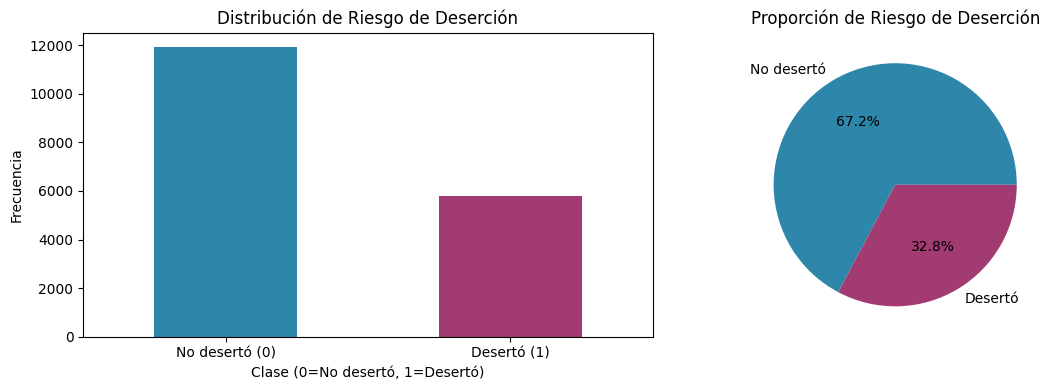

In [9]:
# ============================================
# EDA - PASO 1: Distribución de la variable objetivo
# ============================================

import matplotlib.pyplot as plt

# Gráfica de distribución
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Gráfica de barras
df_clean['riesgo_desercion'].value_counts().plot(kind='bar', ax=axes[0], color=['#2E86AB', '#A23B72'])
axes[0].set_title('Distribución de Riesgo de Deserción')
axes[0].set_xlabel('Clase (0=No desertó, 1=Desertó)')
axes[0].set_ylabel('Frecuencia')
axes[0].set_xticklabels(['No desertó (0)', 'Desertó (1)'], rotation=0)

# Gráfica de pastel
df_clean['riesgo_desercion'].value_counts().plot(kind='pie', ax=axes[1],
                                                  autopct='%1.1f%%',
                                                  colors=['#2E86AB', '#A23B72'],
                                                  labels=['No desertó', 'Desertó'])
axes[1].set_title('Proporción de Riesgo de Deserción')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

In [10]:
# ============================================
# EDA - PASO 2: Correlaciones
# ============================================

# Seleccionar solo variables numéricas
variables_numericas = df_clean.select_dtypes(include=['int64', 'float64']).columns.tolist()
print("Variables numéricas:")
print(variables_numericas)

# Matriz de correlaciones de Pearson
corr_pearson = df_clean[variables_numericas].corr(method='pearson')

# Matriz de correlaciones de Spearman
corr_spearman = df_clean[variables_numericas].corr(method='spearman')

# Mostrar correlaciones con la variable objetivo
print("\n=== CORRELACIONES CON RIESGO_DESERCION (Pearson) ===")
print(corr_pearson['riesgo_desercion'].sort_values(ascending=False))

print("\n=== CORRELACIONES CON RIESGO_DESERCION (Spearman) ===")
print(corr_spearman['riesgo_desercion'].sort_values(ascending=False))

Variables numéricas:
['punt_ingles', 'punt_matematicas', 'punt_sociales_ciudadanas', 'punt_c_naturales', 'punt_lectura_critica', 'punt_global', 'riesgo_desercion']

=== CORRELACIONES CON RIESGO_DESERCION (Pearson) ===
riesgo_desercion            1.000000
punt_ingles                -0.524919
punt_matematicas           -0.671682
punt_lectura_critica       -0.676901
punt_c_naturales           -0.685802
punt_sociales_ciudadanas   -0.708185
punt_global                -0.767499
Name: riesgo_desercion, dtype: float64

=== CORRELACIONES CON RIESGO_DESERCION (Spearman) ===
riesgo_desercion            1.000000
punt_ingles                -0.559868
punt_lectura_critica       -0.699998
punt_matematicas           -0.704210
punt_c_naturales           -0.714762
punt_sociales_ciudadanas   -0.724881
punt_global                -0.812922
Name: riesgo_desercion, dtype: float64


In [11]:
# ============================================
# EDA - PASO 3: Multicolinealidad (VIF)
# ============================================

from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

# Usar solo variables numéricas
X_vif = df_clean[variables_numericas].dropna()

# Calcular VIF
vif_data = pd.DataFrame()
vif_data["Variable"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i)
                   for i in range(len(X_vif.columns))]

# Ordenar por VIF
vif_data = vif_data.sort_values('VIF', ascending=False)
print(vif_data)

                   Variable           VIF
5               punt_global  12531.615144
1          punt_matematicas   1015.003673
2  punt_sociales_ciudadanas    966.955796
4      punt_lectura_critica    760.993803
3          punt_c_naturales    743.120158
0               punt_ingles    102.335940
6          riesgo_desercion      2.476436


In [12]:
# ============================================
# EDA - PASO 4: Desbalance de clases
# ============================================

print("=== DESBALANCE DE CLASES ===")
conteo = df_clean['riesgo_desercion'].value_counts()
porcentaje = df_clean['riesgo_desercion'].value_counts(normalize=True) * 100

print(f"Clase 0 (No desertó): {conteo[0]:,} ({porcentaje[0]:.2f}%)")
print(f"Clase 1 (Desertó): {conteo[1]:,} ({porcentaje[1]:.2f}%)")
print(f"\nRatio de desbalance: {conteo[0]/conteo[1]:.2f}:1")

=== DESBALANCE DE CLASES ===
Clase 0 (No desertó): 11,912 (67.24%)
Clase 1 (Desertó): 5,803 (32.76%)

Ratio de desbalance: 2.05:1


In [13]:
# ============================================
# FEATURE ENGINEERING - PASO 1: Crear variables
# ============================================

# 1. Promedio de puntajes por área
df_clean['promedio_puntajes'] = df_clean[['punt_ingles', 'punt_matematicas',
                                          'punt_sociales_ciudadanas',
                                          'punt_c_naturales',
                                          'punt_lectura_critica']].mean(axis=1)

# 2. Ratio de personas por cuarto (hacinamiento)
df_clean['fami_personashogar'] = pd.to_numeric(df_clean['fami_personashogar'], errors='coerce')
df_clean['fami_cuartoshogar'] = pd.to_numeric(df_clean['fami_cuartoshogar'], errors='coerce')
df_clean['ratio_hacinamiento'] = df_clean['fami_personashogar'] / df_clean['fami_cuartoshogar']

# 3. Nivel educativo de los padres (convertir a ordinal)
mapa_educacion = {
    'Ninguno': 0,
    'Primaria incompleta': 1,
    'Primaria completa': 2,
    'Secundaria (Bachillerato) incompleta': 3,
    'Secundaria (Bachillerato) completa': 4,
    'Técnica o tecnológica incompleta': 5,
    'Técnica o tecnológica completa': 6,
    'Educación profesional incompleta': 7,
    'Educación profesional completa': 8,
    'Postgrado': 9,
    'No sabe': 0,
    'No Aplica': 0
}

df_clean['educacion_madre_ord'] = df_clean['fami_educacionmadre'].map(mapa_educacion)
df_clean['educacion_padre_ord'] = df_clean['fami_educacionpadre'].map(mapa_educacion)

# 4. Estrato socioeconómico (convertir a numérico)
mapa_estrato = {
    'Sin Estrato': 0,
    'Estrato 1': 1,
    'Estrato 2': 2,
    'Estrato 3': 3,
    'Estrato 4': 4,
    'Estrato 5': 5,
    'Estrato 6': 6
}
df_clean['estrato_num'] = df_clean['fami_estratovivienda'].map(mapa_estrato)

# Verificar las nuevas variables
print("Nuevas variables creadas:")
print(df_clean[['promedio_puntajes', 'ratio_hacinamiento',
                'educacion_madre_ord', 'educacion_padre_ord',
                'estrato_num']].describe())

Nuevas variables creadas:
       promedio_puntajes  ratio_hacinamiento  educacion_madre_ord  \
count       17715.000000                 0.0         17715.000000   
mean           53.832989                 NaN             3.762913   
std             8.687469                 NaN             2.279824   
min             0.000000                 NaN             0.000000   
25%            47.600000                 NaN             2.000000   
50%            53.400000                 NaN             4.000000   
75%            59.600000                 NaN             4.000000   
max            91.200000                 NaN             9.000000   

       educacion_padre_ord   estrato_num  
count         17715.000000  17715.000000  
mean              3.340333      1.901214  
std               2.351796      0.705513  
min               0.000000      0.000000  
25%               1.000000      1.000000  
50%               3.000000      2.000000  
75%               4.000000      2.000000  
max     

In [14]:
# ============================================
# FEATURE ENGINEERING - PASO 2: Codificación
# ============================================

# Variables categóricas a codificar (One-Hot Encoding)
variables_categoricas = ['estu_genero', 'cole_area_ubicacion', 'cole_caracter',
                         'cole_jornada', 'cole_calendario', 'fami_tienecomputador',
                         'fami_tieneinternet', 'fami_tieneautomovil',
                         'fami_tienelavadora']

# Aplicar One-Hot Encoding
df_encoded = pd.get_dummies(df_clean, columns=variables_categoricas, drop_first=True)

print(f"Variables antes de codificar: {df_clean.shape[1]}")
print(f"Variables después de codificar: {df_encoded.shape[1]}")
print(f"\nNuevas columnas creadas: {df_encoded.shape[1] - df_clean.shape[1]}")

Variables antes de codificar: 57
Variables después de codificar: 62

Nuevas columnas creadas: 5


In [15]:
# ============================================
# FEATURE ENGINEERING - PASO 3: Selección de variables
# ============================================

# Variables que NO usaremos para el modelo (por multicolinealidad o irrelevancia)
variables_excluir = [
    'punt_ingles', 'punt_matematicas', 'punt_sociales_ciudadanas',
    'punt_c_naturales', 'punt_lectura_critica',  # Multicolinealidad
    'estu_consecutivo', 'cole_cod_dane_establecimiento', 'cole_cod_dane_sede',
    'cole_codigo_icfes', 'cole_nombre_establecimiento', 'cole_nombre_sede',
    'estu_fechanacimiento', 'estu_cod_depto_presentacion', 'estu_cod_mcpio_presentacion',
    'estu_cod_reside_depto', 'estu_cod_reside_mcpio', 'estu_mcpio_presentacion',
    'estu_depto_presentacion', 'estu_mcpio_reside', 'estu_depto_reside',
    'cole_cod_depto_ubicacion', 'cole_cod_mcpio_ubicacion', 'cole_depto_ubicacion',
    'cole_mcpio_ubicacion', 'estu_tipodocumento', 'estu_nacionalidad',
    'estu_pais_reside', 'estu_privado_libertad', 'estu_estadoinvestigacion',
    'estu_estudiante', 'cole_bilingue', 'desemp_ingles'
]

# Eliminar variables que no existen en el dataframe
variables_excluir = [v for v in variables_excluir if v in df_encoded.columns]

# Crear dataset final
df_final = df_encoded.drop(columns=variables_excluir)

print(f"Variables finales: {df_final.shape[1]}")
print(f"\nColumnas finales:")
print(df_final.columns.tolist())

Variables finales: 30

Columnas finales:
['periodo', 'cole_genero', 'cole_naturaleza', 'cole_sede_principal', 'fami_cuartoshogar', 'fami_educacionmadre', 'fami_educacionpadre', 'fami_estratovivienda', 'fami_personashogar', 'punt_global', 'riesgo_desercion', 'promedio_puntajes', 'ratio_hacinamiento', 'educacion_madre_ord', 'educacion_padre_ord', 'estrato_num', 'estu_genero_M', 'cole_area_ubicacion_URBANO', 'cole_caracter_NO APLICA', 'cole_caracter_TÉCNICO', 'cole_caracter_TÉCNICO/ACADÉMICO', 'cole_jornada_MAÑANA', 'cole_jornada_NOCHE', 'cole_jornada_SABATINA', 'cole_jornada_TARDE', 'cole_jornada_UNICA', 'fami_tienecomputador_Si', 'fami_tieneinternet_Si', 'fami_tieneautomovil_Si', 'fami_tienelavadora_Si']


In [16]:
# ============================================
# FEATURE ENGINEERING - PASO 4: Guardar dataset
# ============================================

# Guardar el dataset final
df_final.to_csv('dataset_final.csv', index=False)
print("✅ Dataset guardado como 'dataset_final.csv'")
print(f"Filas: {df_final.shape[0]}")
print(f"Columnas: {df_final.shape[1]}")

✅ Dataset guardado como 'dataset_final.csv'
Filas: 17715
Columnas: 30


In [17]:
# Eliminar ratio_hacinamiento porque quedó vacío
df_final = df_final.drop(columns=['ratio_hacinamiento'])
print(f"Variables finales: {df_final.shape[1]}")
print(f"Filas: {df_final.shape[0]}")

Variables finales: 29
Filas: 17715
